<a href="https://colab.research.google.com/github/bhargavanarasimhaai24/Statistical-Modelling/blob/main/2.%20Multiple_Linear_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Multiple Linear Regression from Scratch

## Objective
Build a multiple linear regression model using **NumPy**, understand how its parameters are estimated, and evaluate its predictions.

This notebook uses two input features (`x1` and `x2`) to predict a continuous target (`y`). The original dataset contains 20 observations. The real-world meaning and source of these variables were not included in the original notebook, so they are intentionally kept as generic feature names.

## Learning outcomes
- Understand the multiple linear regression equation.
- Implement parameter estimation without using Scikit-learn's regression estimator.
- Generate predictions using the fitted model.
- Evaluate model fit using MAE, MSE, RMSE, and R².
- Inspect predictions and residuals visually.

> **Important:** All 20 observations are used to fit and evaluate the model in this introductory demonstration. The reported metrics are *training metrics* and should not be interpreted as performance on unseen data.


## 1. Theory

For two independent variables, the **Multiple Linear Regression** model is:

$$
\hat{y} = \beta_0 + \beta_1 x_1 + \beta_2 x_2
$$

Where:

- $\beta_0$: Intercept
- $\beta_1, \beta_2$: Coefficients learned from the data
- $x_1, x_2$: Input features
- $\hat{y}$: Predicted target

### Matrix Representation

In matrix form, the model is represented as:

$$
\hat{\mathbf{y}} = \mathbf{X}\boldsymbol{\beta}
$$

### Ordinary Least Squares (OLS)

The Ordinary Least Squares method minimizes the **sum of squared errors** between the actual and predicted values.

The objective function is:

$$
\min_{\boldsymbol{\beta}}
\left\| \mathbf{X}\boldsymbol{\beta} - \mathbf{y} \right\|_2^2
$$

### Normal Equation

The analytical solution to the OLS problem is given by:

$$
\boldsymbol{\beta} =
(\mathbf{X}^T\mathbf{X})^{-1}
\mathbf{X}^T\mathbf{y}
$$

**Limitation:** Directly calculating the matrix inverse can be numerically unstable or fail when the matrix is singular.

**Implementation:** In this notebook, `numpy.linalg.lstsq()` is used to obtain a least-squares solution more robustly without explicitly calculating the matrix inverse.

## 2. Import libraries

In [1]:
import numpy as np
import pandas as pd
from sympy import Matrix
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score

## 3. Load the dataset

The following values are retained from the original notebook. Replace these arrays with a documented dataset if you later identify the original source.

In [2]:
y = np.array([
    17.68, 12.50, 13.03, 15.88, 14.75,
    19.11, 9.00, 18.83, 80.24, 22.50,
    41.33, 22.00, 14.50, 20.75, 25.00,
    30.00, 16.35, 20.00, 10.50, 36.10
], dtype=float)

x1 = np.array([
    7, 3, 3, 4, 6, 7, 2, 7, 30, 5,
    16, 10, 4, 6, 9, 10, 6, 7, 3, 17
], dtype=float)

x2 = np.array([
    560, 220, 340, 80, 150, 330, 110, 210, 1460, 605,
    688, 215, 255, 462, 448, 776, 200, 132, 36, 770
], dtype=float)

ones = np.ones(x1.shape)

X = np.column_stack((ones, x1, x2))

print(f"Number of observations: {X.shape[0]}")
print(f"Number of features: {X.shape[1]}")
print(f"Feature matrix shape: {X.shape}")
print(f"Target vector shape: {y.shape}")
print("X =", )
display(Matrix(X))


Number of observations: 20
Number of features: 3
Feature matrix shape: (20, 3)
Target vector shape: (20,)
X =


Matrix([
[1.0,  7.0,  560.0],
[1.0,  3.0,  220.0],
[1.0,  3.0,  340.0],
[1.0,  4.0,   80.0],
[1.0,  6.0,  150.0],
[1.0,  7.0,  330.0],
[1.0,  2.0,  110.0],
[1.0,  7.0,  210.0],
[1.0, 30.0, 1460.0],
[1.0,  5.0,  605.0],
[1.0, 16.0,  688.0],
[1.0, 10.0,  215.0],
[1.0,  4.0,  255.0],
[1.0,  6.0,  462.0],
[1.0,  9.0,  448.0],
[1.0, 10.0,  776.0],
[1.0,  6.0,  200.0],
[1.0,  7.0,  132.0],
[1.0,  3.0,   36.0],
[1.0, 17.0,  770.0]])

## 4. Exploratory data analysis

Inspect the values and feature relationships before fitting the model.

In [3]:
data = pd.DataFrame({
    "x1": x1,
    "x2": x2,
    "y": y
})

display(data.head())
display(data.describe())


,x1,x2,y
0,7.0,560.0,17.68
1,3.0,220.0,12.50
2,3.0,340.0,13.03
3,4.0,80.0,15.88
4,6.0,150.0,14.75


,x1,x2,y
count,20.000000,20.000000,20.000000
mean,8.100000,402.350000,23.002500
std,6.512336,339.042968,15.745146
min,2.000000,36.000000,9.000000
25%,4.000000,187.500000,14.687500
50%,6.500000,292.500000,18.970000
75%,9.250000,571.250000,23.125000
max,30.000000,1460.000000,80.240000


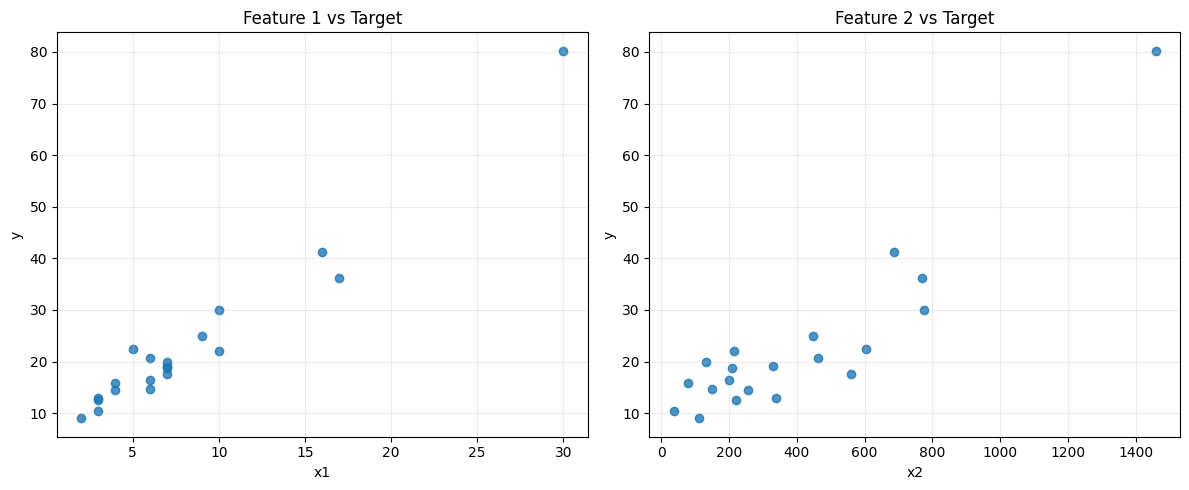

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(x1, y, alpha=0.8)
axes[0].set(title="Feature 1 vs Target", xlabel="x1", ylabel="y")
axes[0].grid(alpha=0.25)

axes[1].scatter(x2, y, alpha=0.8)
axes[1].set(title="Feature 2 vs Target", xlabel="x2", ylabel="y")
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()


## 5. Implement Multiple Linear Regression from scratch

The model below:
- Adds the intercept column internally.
- Checks input dimensions and invalid numeric values.
- Estimates coefficients using `np.linalg.lstsq()`.
- Provides a separate `predict()` method.

No Scikit-learn regression model is used.


In [5]:
class MultipleLinearRegression:
    def __init__(self):
      self.coefficients=None
    def fit(self, X, y):
      self.coefficients = np.linalg.inv(X.T@X)@X.T@y
    def predict(self, X):
      return X@self.coefficients

## 6. Train the model

In [6]:
model = MultipleLinearRegression()
model.fit(X, y)

intercept = model.coefficients[0]
feature_coefficients = model.coefficients[1:]

print(f"Intercept (beta_0): {intercept:.6f}")
for index, coefficient in enumerate(feature_coefficients, start=1):
    print(f"Coefficient (beta_{index}): {coefficient:.6f}")


Intercept (beta_0): 3.470719
Coefficient (beta_1): 1.818826
Coefficient (beta_2): 0.011928


## 7. Write the fitted equation

In [7]:
equation = (
    f"y_hat = {intercept:.4f}"
    + "".join(
        f" + ({coefficient:.4f} * x{index})"
        for index, coefficient in enumerate(feature_coefficients, start=1)
    )
)

print("Fitted regression equation:")
print(equation)


Fitted regression equation:
y_hat = 3.4707 + (1.8188 * x1) + (0.0119 * x2)


## 8. Make predictions

Use the model's `predict()` method to calculate the predicted target values. Then compare actual and predicted values.


In [8]:
y_pred = model.predict(X)

comparison = pd.DataFrame({
    "Actual": y,
    "Predicted": y_pred,
    "Residual": y - y_pred
})

display(comparison.round(4))


,Actual,Predicted,Residual
0,17.68,22.8823,-5.2023
1,12.50,11.5514,0.9486
2,13.03,12.9828,0.0472
3,15.88,11.7003,4.1797
4,14.75,16.1729,-1.4229
5,19.11,20.1388,-1.0288
6,9.00,8.4205,0.5795
7,18.83,18.7074,0.1226
8,80.24,75.4506,4.7894
9,22.50,19.7814,2.7186


## 9. Evaluate the model

We calculate four commonly used regression metrics:

- **MAE:** average absolute prediction error.
- **MSE:** average squared prediction error.
- **RMSE:** square root of MSE, expressed in the target's units.
- **R²:** proportion of target variance explained by the fitted model on this dataset.

These are training-set metrics because the model was fitted on all observations.


In [9]:
def regression_metrics(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)

    errors = y_true - y_pred
    mae = np.mean(np.abs(errors))
    mse = np.mean(errors ** 2)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)

    return {
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2": r2
    }

metrics = regression_metrics(y, y_pred)

for metric, value in metrics.items():
    print(f"{metric}: {value:.4f}")


MAE: 1.8871
MSE: 7.4432
RMSE: 2.7282
R2: 0.9684


## 10. Actual vs predicted values

Points closer to the dashed diagonal line indicate predictions closer to the actual values.

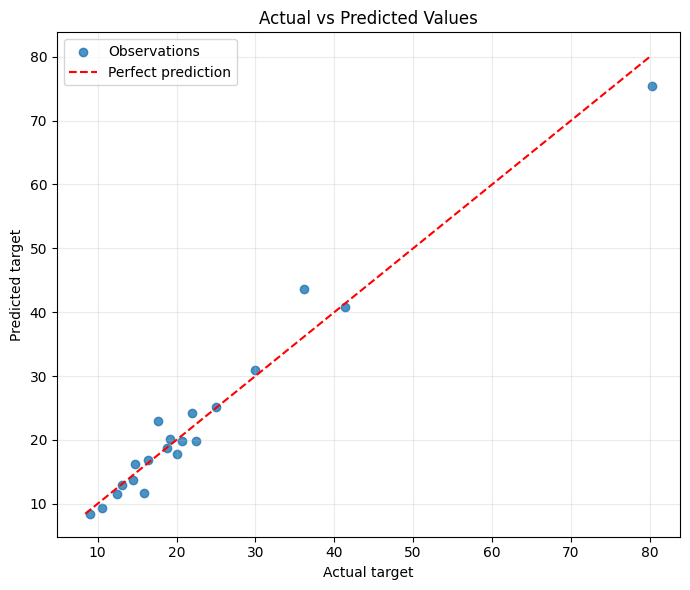

In [10]:
lower = min(y.min(), y_pred.min())
upper = max(y.max(), y_pred.max())

plt.figure(figsize=(7, 6))
plt.scatter(y, y_pred, alpha=0.8, label="Observations")
plt.plot([lower, upper], [lower, upper], "r--", label="Perfect prediction")
plt.xlabel("Actual target")
plt.ylabel("Predicted target")
plt.title("Actual vs Predicted Values")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


## 12. Interpretation and limitations

### Interpretation
- The intercept is the model's predicted target when all input features are zero. This may or may not have practical meaning within the dataset.
- Each coefficient represents the model's estimated change in the predicted target for a one-unit increase in that feature, **holding the other feature constant**.
- The sign and magnitude of coefficients should be interpreted in the context of the feature units and data.

### Limitations
1. The dataset contains only 20 observations, which is very small for drawing reliable conclusions.
2. The original notebook did not specify the dataset source or the real-world meaning of `x1`, `x2`, and `y`.
3. The metrics are calculated on the training data; they do not measure performance on unseen observations.
4. Linear regression assumes a linear relationship in the model parameters. Residual analysis and domain knowledge are needed to assess whether this is reasonable.
5. Feature scale and possible multicollinearity should be examined before drawing conclusions about individual coefficients.



## Conclusion

A multiple linear regression model was implemented from scratch using NumPy. The notebook demonstrates parameter estimation, prediction, and regression metrics. The results should be treated as an educational demonstration until the dataset source is documented and performance is tested on unseen data.
